In [89]:
import numpy as np
import pandas as pd
import jax
jax.config.update("jax_enable_x64", True)
import jax.numpy as jnp
import optax
import unittest
from functools import partial 

import matplotlib.pyplot as plt

In [112]:
@jax.jit
def loss_fn(z, inds, Sigma_tilde):
    """
        z: vector supporting K(z)
        Sigma_tilde: matrix of observed (privatized) covariance entries
    """
    # defines jax-numpy loss
    d = Sigma_tilde.shape[0]
    K_z = get_K(z, inds, d)
    
    #log_det_term = jnp.log(jnp.linalg.det(K_z))
    log_det_term = logdet_psd(K_z)
    
    trace_term = jnp.trace(jnp.matmul(K_z, Sigma_tilde))

    return -log_det_term + trace_term


def get_K(z, inds, d):
    """
    z: (jax array) vector supporting precision matrix estimate K(z)
    inds: (numpy array) list of the lower triangular nonzero element indices in Sigma_tilde
    d: dimension of Sigma_tilde
    """
    
    K = jnp.zeros((d, d))
    
    # update the matrix
    K = K.at[inds[:, 0], inds[:, 1]].set(z)
    K = K.at[inds[:, 1], inds[:, 0]].set(z)
    
    return K


def initialize_z(Sigma_tilde):
    """
        Sigma_tilde: matrix of observed (privatized) covariance entries
    """

    d = Sigma_tilde.shape[0]
    
    nonzero_off_inds = get_strict_lower_triangle_nonzero(Sigma_tilde)
    print(nonzero_off_inds)

    z_init = []

    for i in range(d):
        z_init.append(max(0.01, 1.0 / float(Sigma_tilde[i,i])))
    for tup in nonzero_off_inds:
        z_init.append(0)

    z_init = jnp.array(z_init)
    inds = np.concatenate(([(i,i) for i in range(d)], nonzero_off_inds))
        
    return z_init, inds

    
def optimize_lbfgs(Sigma_tilde, z, inds, max_iters=100, verbose=True):
    """
        Sigma_tilde: matrix of observed (privatized) covariance entries
        z: vector supporting K(z)
    """

    d = Sigma_tilde.shape[0]
    
    # Linesearch, comment/uncomment the desired one
    # linesearch = optax.scale_by_backtracking_linesearch(max_backtracking_steps=15)
    linesearch = optax.scale_by_zoom_linesearch(max_linesearch_steps=15)
    
    # Optimizer
    opt = optax.chain(
        optax.lbfgs(),
        # Compare with or without linesearch by commenting this line
        linesearch,
    )
    
    # Initialize
    state = opt.init(z)

    loss_fn_wrapper = partial(loss_fn, inds=inds, Sigma_tilde=Sigma_tilde)

    g_vals = []
    
    # Run optimization
    for i in range(max_iters):
        v, g = jax.value_and_grad(loss_fn_wrapper)(z)
        
        updates, state = opt.update(g, state, z, value=v, grad=g, value_fn=loss_fn_wrapper)
        z = optax.apply_updates(z, updates)
        #z = jnp.add(z, updates)

        if verbose:
            print(f'iter: {i}, value:{v:.7e}')
            print(f"grad sum: {jnp.sum(jnp.abs(g))}")
            print(f"grad: {g}")
            print("z", z)
        
            K_z = get_K(z, inds, d)
            # if not is_positive_definite(K_z):
            #     print("NOT PD")
            #     #z = binary_search_pd_point(z, g)
            log_det_1 = logdet_psd(K_z)
            s, log_det_2 = jnp.linalg.slogdet(K_z)
            print("compare log det", log_det_1, log_det_2)
            print("\n")

        g_vals.append(jnp.sum(jnp.abs(g)))
        
    plt.plot(g_vals)
    plt.show()
    
    return z


# helpers # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # 

def is_positive_definite(M):
    return jnp.all(jnp.linalg.eigvalsh(M) > 0)

def get_strict_lower_triangle_nonzero(M):
    # lower triangle indices excluding the diagonal
    lower_triangle_indices = np.tril_indices(M.shape[0], k=-1)
    
    # nonzero elements in the lower triangle
    nonzero_mask = M[lower_triangle_indices] != 0
    filtered_indices = (lower_triangle_indices[0][nonzero_mask], lower_triangle_indices[1][nonzero_mask])
    
    # zip indices together into tuples
    indices_tuples = list(zip(filtered_indices[0].tolist(), filtered_indices[1].tolist()))
    
    return indices_tuples


@jax.jit
def logdet_psd(A):
    # Compute the Cholesky decomposition
    L = jnp.linalg.cholesky(A)

    # Check if any entry of the Cholesky factor is NaN
    is_nan = jnp.any(jnp.isnan(L))

    def nan_case(_):
        return -jnp.inf

    def valid_case(L):
        diag_L = jnp.diag(L)
        log_det = 2 * jnp.sum(jnp.log(diag_L))
        return log_det

    # Use jax.cond to choose between the cases
    return jax.lax.cond(is_nan, nan_case, valid_case, L)

def generate_multivariate_normal_data(n, d):
    mean = np.zeros(d)
    
    # Define a random positive definite covariance matrix (4x4)
    A = np.random.rand(n, d)
    covariance_matrix = np.dot(A.transpose(), A)
    
    # Generate the multivariate normal dataset
    dataset = np.random.multivariate_normal(mean, covariance_matrix, n)
    
    return dataset, covariance_matrix


def get_Sigma_tilde_d4(cov):
    M = np.zeros_like(cov)
    
    # copy diagonal
    np.fill_diagonal(M, np.diag(cov))
    
    # copy the [0,3] and [3,0] elements
    M[0, 3] = cov[0, 3]
    M[3, 0] = cov[3, 0]
    
    return M

def get_Sigma_tilde_d15(cov, off_diagonal_percentage=0.15):
    # by ChatGPT, review
    d = cov.shape[0]
    assert d == 15, "The function is designed for 15x15 matrices only."
    
    M = np.zeros_like(cov)
    
    # Copy diagonal
    np.fill_diagonal(M, np.diag(cov))
    
    # Number of off-diagonal entries to fill
    num_off_diagonal = int(off_diagonal_percentage * (d * (d - 1)) / 2)
    
    # Generate all possible off-diagonal indices
    off_diagonal_indices = [(i, j) for i in range(d) for j in range(i+1, d)]
    
    # Randomly select indices to fill
    selected_indices = np.random.choice(len(off_diagonal_indices), num_off_diagonal, replace=False)
    
    for idx in selected_indices:
        i, j = off_diagonal_indices[idx]
        M[i, j] = cov[i, j]
        M[j, i] = cov[j, i]
    
    return M

def is_positive_definite(K):
    return jnp.all(jnp.linalg.eigvalsh(K) > 0)

# tests # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # # 

class TestAuxiliaryFunctions(unittest.TestCase):
    def test_get_K(self):
        d = 3
        z = np.array([1., 2., 3., 4., 5.])
        # Updated indices to be within bounds for a 3x3 matrix
        inds = np.array([(0, 0), (1, 1), (2, 2), (1, 0), (2, 0)])
        
        K_result = get_K(z, inds, d)
        
        # Updated expected result matrix based on the new indices
        K_true = np.array([[1., 4., 5.],
                           [4., 2., 0.],
                           [5., 0., 3.]])
        
        assert np.allclose(K_result, K_true, atol=1e-10), "test_get_K failed"

    def test_get_K(self):
        Sigma_tilde = np.array([[1000., 0., 4.],
                               [0., 2., 0.],
                               [4., 0., 3.]])
        d = Sigma_tilde.shape[0]
        
        z_true = np.array([0.01, 1/2., 1/3., 0.])  
        z_init, inds_init = initialize_z(Sigma_tilde)

        for i in range(d):
            self.assertTrue(np.allclose(z_true, z_init, atol=1e-10)), "test_get_K failed"
            
unittest.main(argv=[''], verbosity=2, exit=False)

test_get_K (__main__.TestAuxiliaryFunctions) ... ok
test_initialize_z (__main__.TestAuxiliaryFunctions) ... ok

----------------------------------------------------------------------
Ran 2 tests in 0.016s

OK


[(2, 0)]


Sigma_true, [[26.54863137  1.12558197 -0.92236391 -0.29460695]
 [ 1.12558197  4.87413218 -0.10834532  0.20117863]
 [-0.92236391 -0.10834532  5.23528579 -0.19909199]
 [-0.29460695  0.20117863 -0.19909199 15.01169162]]
Prec_true, [[ 0.03827682 -0.00873201  0.00659933  0.00095573]
 [-0.00873201  0.20736026  0.00264208 -0.00291526]
 [ 0.00659933  0.00264208  0.19232948  0.00264487]
 [ 0.00095573 -0.00291526  0.00264487  0.06670765]]
Sigma_tilde, [[26.54863137  0.          0.         -0.29460695]
 [ 0.          4.87413218  0.          0.        ]
 [ 0.          0.          5.23528579  0.        ]
 [-0.29460695  0.          0.         15.01169162]]
Prec_tilde, [[0.03767493 0.         0.         0.00073938]
 [0.         0.20516473 0.         0.        ]
 [0.         0.         0.19101154 0.        ]
 [0.00073938 0.         0.         0.06662925]]
[(3, 0)]
iter: 0, value:1.3227171e+01
grad sum: 0.5892138980620875
grad: [-3.55271368e-15  0.00000000e+00 -8.88178420e-16  5.32907052e-15
 -5.892138

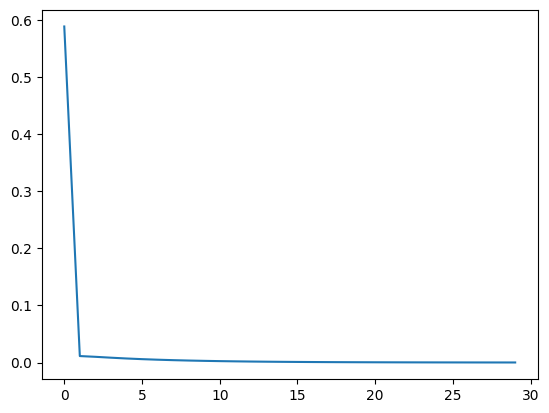

In [99]:
adult_path = "/Users/ceciliaferrando/Documents/UMASS/RESEARCH/DPsynthesisML/hd-datasets-master/clean/adult.csv"
adult_data_d4 = pd.read_csv(adult_path)[["age", "workclass", "fnlwgt", "education"]]

Sigma_true = adult_data_d4.cov().to_numpy()
Prec_true = np.linalg.inv(Sigma_true)
d = Sigma_true.shape[0]

Sigma_tilde = get_Sigma_tilde_d4(Sigma_true)
#Sigma_tilde = Sigma_tilde + np.random.normal(0, 0.01, size=Sigma_tilde.shape)
Prec_tilde = np.linalg.inv(Sigma_tilde)

print(f"Sigma_true, {Sigma_true}")
print(f"Prec_true, {Prec_true}")
print(f"Sigma_tilde, {Sigma_tilde}")
print(f"Prec_tilde, {Prec_tilde}")

z_init, inds_init = initialize_z(Sigma_tilde)
K_z_init = get_K(z_init,  inds_init, d)
det_init = np.linalg.det(K_z_init)

z_opt = optimize_lbfgs(Sigma_tilde, z_init, inds_init, max_iters=30)
#z_opt = optimize_lbfgs_check(Sigma_tilde, z_init, max_iters=100, initial_step_size=1.0, step_size_reduction=0.5, min_step_size=1e-6)


In [92]:
K_z_opt = get_K(z_opt, inds_init, 4)

print("Sigma_true", Sigma_true)
print("Prec_true", Prec_true)
print("\n")
print("Sigma_tilde", Sigma_tilde)
print("Prec_tilde", Prec_tilde)
print("\n")
print("Sigma_opt", np.linalg.inv(K_z_opt))
print("Prec_opt", K_z_opt)

Sigma_true [[26.54863137  1.12558197 -0.92236391 -0.29460695]
 [ 1.12558197  4.87413218 -0.10834532  0.20117863]
 [-0.92236391 -0.10834532  5.23528579 -0.19909199]
 [-0.29460695  0.20117863 -0.19909199 15.01169162]]
Prec_true [[ 0.03827682 -0.00873201  0.00659933  0.00095573]
 [-0.00873201  0.20736026  0.00264208 -0.00291526]
 [ 0.00659933  0.00264208  0.19232948  0.00264487]
 [ 0.00095573 -0.00291526  0.00264487  0.06670765]]


Sigma_tilde [[26.54863137  0.          0.         -0.29460695]
 [ 0.          4.87413218  0.          0.        ]
 [ 0.          0.          5.23528579  0.        ]
 [-0.29460695  0.          0.         15.01169162]]
Prec_tilde [[0.03767493 0.         0.         0.00073938]
 [0.         0.20516473 0.         0.        ]
 [0.         0.         0.19101154 0.        ]
 [0.00073938 0.         0.         0.06662925]]


Sigma_opt [[26.54866594  0.          0.         -0.29460014]
 [ 0.          4.87413218  0.          0.        ]
 [ 0.          0.          5.2352857

[(2, 1), (4, 1), (6, 5), (8, 1), (8, 3), (9, 1), (9, 7), (9, 8), (10, 2), (10, 7), (11, 6), (12, 1), (13, 3), (13, 9), (14, 10)]


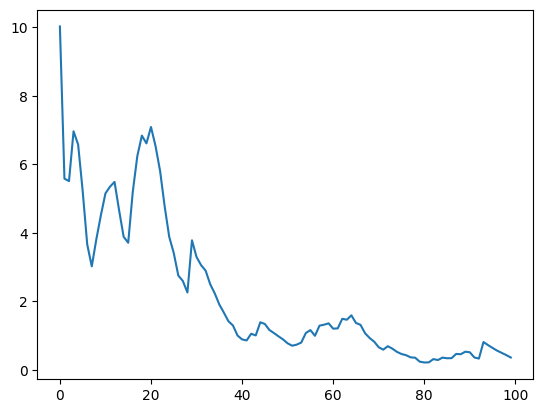

In [95]:
adult_path = "/Users/ceciliaferrando/Documents/UMASS/RESEARCH/DPsynthesisML/hd-datasets-master/clean/adult.csv"
adult_data = pd.read_csv(adult_path)
n, d = adult_data.shape
cov = adult_data.cov().to_numpy()
Sigma_tilde = get_Sigma_tilde_d15(cov, off_diagonal_percentage=0.15)
Prec_tilde = np.linalg.inv(Sigma_tilde)

# print(f"Sigma_true, {Sigma_true}")
# print(f"Prec_true, {Prec_true}")
# print(f"Sigma_tilde, {Sigma_tilde}")
# print(f"Prec_tilde, {Prec_tilde}")

z_init, inds_init = initialize_z(Sigma_tilde)
K_z_init = get_K(z_init, inds_init, d)
det_init = np.linalg.det(K_z_init)

z_opt = optimize_lbfgs(Sigma_tilde, z_init, inds_init, max_iters=100, verbose=False)
#z_opt = optimize_lbfgs_check(Sigma_tilde, z_init, max_iters=100, initial_step_size=1.0, step_size_reduction=0.5, min_step_size=1e-6)

test_get_K (__main__.TestAuxiliaryFunctions) ... FAIL
test_initialize_z (__main__.TestAuxiliaryFunctions) ... FAIL

FAIL: test_get_K (__main__.TestAuxiliaryFunctions)
----------------------------------------------------------------------
Traceback (most recent call last):
  File "/var/folders/_v/3q83tdz16dz82yk206z719v40000gn/T/ipykernel_96724/3495875664.py", line 218, in test_get_K
    self.assertTrue(np.allclose(K_result, K_true, atol=1e-10))
AssertionError: False is not true

FAIL: test_initialize_z (__main__.TestAuxiliaryFunctions)
----------------------------------------------------------------------
Traceback (most recent call last):
  File "/var/folders/_v/3q83tdz16dz82yk206z719v40000gn/T/ipykernel_96724/3495875664.py", line 230, in test_initialize_z
    self.assertTrue(np.allclose(z_true, z_init, atol=1e-10))
AssertionError: False is not true

----------------------------------------------------------------------
Ran 2 tests in 0.088s

FAILED (failures=2)


[[1. 0. 0.]
 [0. 2. 0.]
 [0. 0. 3.]]
[(2, 0)]
